In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import torch
import sys
from pathlib import Path
from matplotlib import pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))

import dl_utils

Text(0.5, 1.0, 'RELU Function')

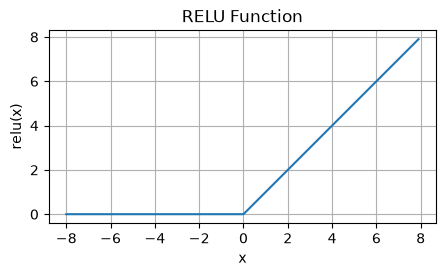

In [8]:
x = torch.arange(-8.0, 8.0, 0.1, requires_grad=True)
y = torch.relu(x)
plt.figure(figsize=(5, 2.5))
plt.plot(x.detach(), y.detach())
plt.grid()
plt.xlabel('x')
plt.ylabel('relu(x)')
plt.title('RELU Function')

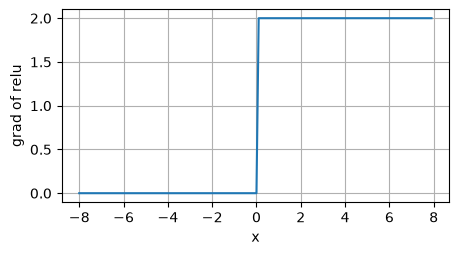

In [10]:
y.backward(torch.ones_like(x), retain_graph=True)
fig, ax = plt.subplots(figsize=(5, 2.5))
ax.set(xlabel='x', ylabel='grad of relu')
ax.plot(x.detach(), x.grad)
ax.grid()

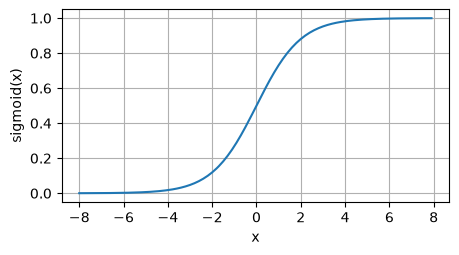

In [ ]:
y = torch.sigmoid(x)
fig, ax = plt.subplots(figsize=(5, 2.5))
ax.set(xlabel='x', ylabel='sigmoid(x)')
ax.plot(x.detach(), y.detach())
ax.grid()


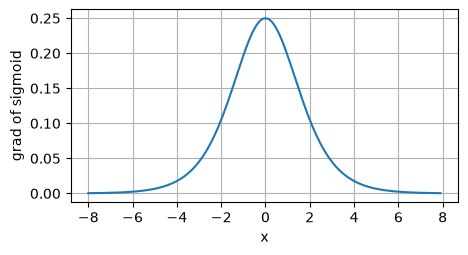

In [16]:
x.grad = None
y.backward(torch.ones_like(x), retain_graph=True)
fig, ax = plt.subplots(figsize=(5, 2.5))
ax.set(xlabel='x', ylabel='grad of sigmoid')
ax.plot(x.detach(), x.grad)
ax.grid()

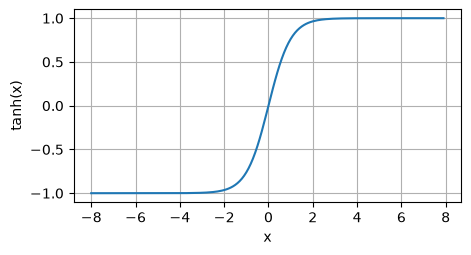

In [17]:
y = torch.tanh(x)
fig, ax = plt.subplots(figsize=(5, 2.5))
ax.set(xlabel='x', ylabel='tanh(x)')
ax.plot(x.detach(), y.detach())
ax.grid()

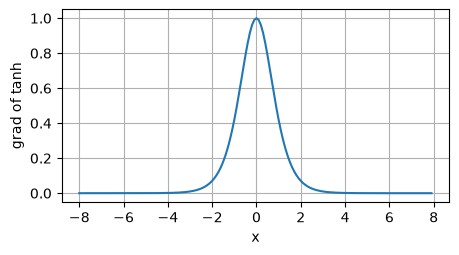

In [18]:
x.grad = None
y.backward(torch.ones_like(x), retain_graph=True)
fig, ax = plt.subplots(figsize=(5, 2.5))
ax.set(xlabel='x', ylabel='grad of tanh')
ax.plot(x.detach(), x.grad)
ax.grid()

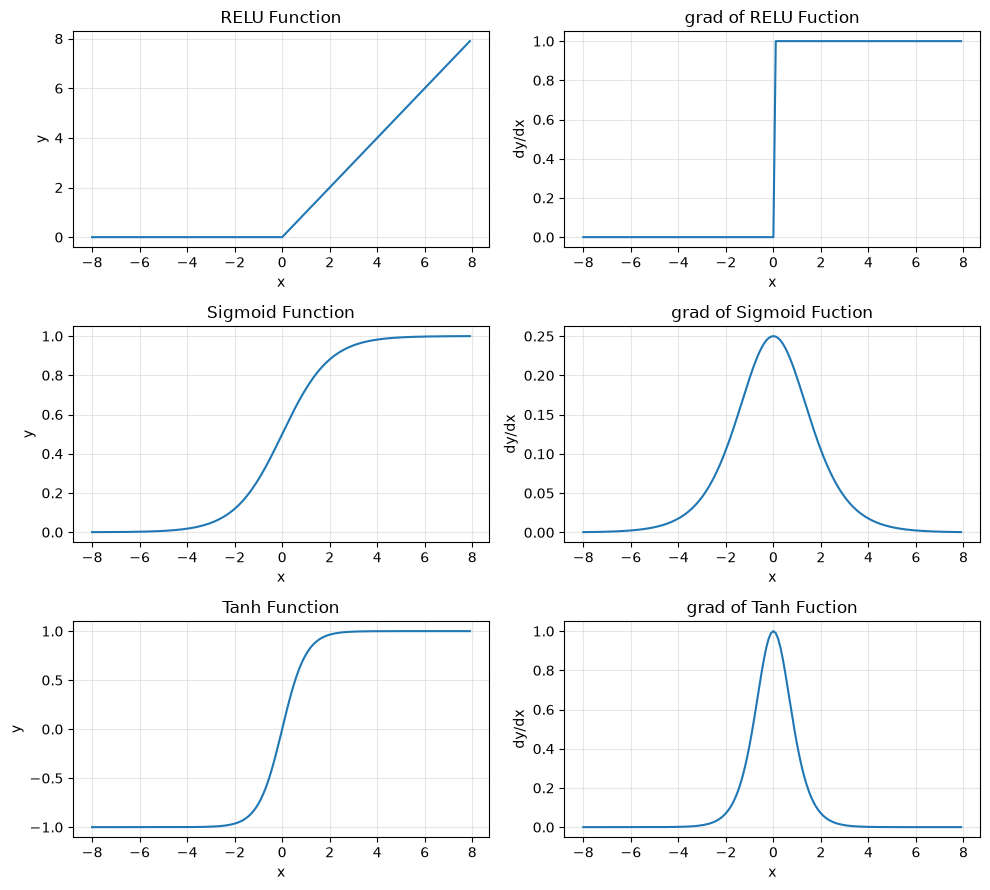

In [19]:
activations = {
    'RELU' : torch.relu,
    'Sigmoid' : torch.sigmoid,
    'Tanh' : torch.tanh
}
fig, axes = plt.subplots(3, 2, figsize=(10, 9))

for i, (name, func) in enumerate(activations.items()):
    x.grad = None
    y = func(x)
    y.sum().backward()
    axes[i, 0].plot(x.detach(), y.detach())
    axes[i, 0].set(xlabel='x', ylabel='y', title=f'{name} Function')
    axes[i, 1].plot(x.detach(), x.grad.detach())
    axes[i, 1].set(xlabel='x', ylabel='dy/dx', title=f'grad of {name} Fuction')
for ax in axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()